# **Estudo sobre Acidentes e Incidentes Aérios em solo Brasileiro**

por Ítalo dos Santos Araujo Chaves

![Imagem de um avião](./images/aeronave-gol-25-anos-jpg)

## Breve Introdução
A aviação é o modal de transporte considerado o mais seguro, fica atrás apenas do elevador.  Cobrindo longas viagens em um curto espaço de tempo, tais aeronaves proveram diversas vantagens para o mundo, tanto comercial quanto a lazer. Infelizmente, como todo meio de transporte, as aeronaves possuem sua conta de tragédias.

## Sobre este estudo
Nesta apresentação, eu estarei utilizando dados abertos disponibilizados pela CENIPA - Centro de Investigação e Prevenção de Acidentes aeronáuticos. Tais arquivos conterão informações sobre ocorrências envolvendo aeronaves em Janeiro de 2007 a Abril de 2026. Você pode acessar dados mais atualizados visitando a página oficial de Dados Abertos Brasileiros, mas, caso deseje, poderá estar realizando o download dos datasets utilizados aqui através dos links de download abaixo.

Para este estudo, utilizarei de dois datasets da CENIPA:

**Ocorrencia.csv**: possui os dados sobre cada ocorrência registrada de em Janeiro de 2007 a Abril de 2026. Código da ocorrência, Data, Motivo da Ocorrência e Localização serão encontrados nesse conjunto de dados.

**Tipo_Ocorrencia.csv**: lista os tipos de ocorrências documentas pelo SIPAER.

**Aeronave.csv**: informações agrupadas sobre as aeronaves envolvidas nas ocorrências registradas no arquivo ocorrencia.csv. Aqui serão encontrados dados como: Modelo da Aeronave, Tipo de Aeronave, Fabricante, Quantidade de Fatalidades, dentre outras.

**Fator_Contribuinte.csv**: Detalhe os fatores contribuintes para ocorrência com os seguintes campos: Código de ocorrencia, Nome do fator, aspecto do fator, Fator condicionante e area. (Futuramente)

**Recomendacao.csv**: lista melhorias de segurança / procedimentos e ações para evitar novos acidentes/incidentes pelos fatores já conhecidos. (Futuramente)


## Perguntas a serem respondidas
Dentre outros insights gerados através deste estudo, quero responder as seguintes perguntas:

Quais são as maiores causas de ocorrências e, eventualmente, queda de aviões?

Como tem sido a progressão desses casos nos últimos anos? Tiveram menos ocorrências ou mais?

Quais os estados que mais possuem ocorrências registradas?

Qual tipo de aeronave possui mais problemas? Aviões, jatos, planadores?

Quais as fabricantes com maior número de defeitos registrados?

Será que durante o pouso é mais comum ter problemas do que durante a decolagem? Ou durante a viagem em si é mais frequente surgir defeitos?

Viagens comerciais regulares tendem a ter mais problemas do que voos fretados?

Quantos incidentes com fatalidades (morte de passageiros e tripulação) temos registro nos últimos 10 anos?



### Importando Bibliotecas

In [148]:
from docutils.nodes import fully_normalize_name
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import random

### Leitura Conjunto de dados

In [149]:
ocorrencia = pd.read_csv(
    './dataset/ocorrencia.csv',
    encoding='latin1',
    sep=';'
)

tipo_ocorrencia = pd.read_csv(
    './dataset/tipo_ocorrencia.csv',
    encoding='latin1',
    sep=';'
)

aeronave = pd.read_csv(
    './dataset/aeronave.csv',
    encoding='latin1',
    sep=';'
)
# fator_contribuinte = pd.read_csv('./dataset/fator_contribuinte.csv', encoding='latin1', sep=';')
# recomendacao = pd.read_csv('./dataset/recomendacao.csv', encoding='latin1', sep=';')

## Limpeza de Dados

O primeiro processo deste estudo será realizar a limpeza e tratativa dos dados. Vamos inicialmente verificar como a tabela do arquivo "ocorrencia.csv" é apresentada.

In [150]:
ocorrencia.head(5)

,codigo_ocorrencia,codigo_ocorrencia1,codigo_ocorrencia2,codigo_ocorrencia3,codigo_ocorrencia4,ocorrencia_classificacao,ocorrencia_latitude,ocorrencia_longitude,ocorrencia_cidade,ocorrencia_uf,...,ocorrencia_dia,ocorrencia_hora,investigacao_aeronave_liberada,investigacao_status,divulgacao_relatorio_numero,divulgacao_relatorio_publicado,divulgacao_dia_publicacao,total_recomendacoes,total_aeronaves_envolvidas,ocorrencia_saida_pista
0,88808,88808,88808,88808,88808,INCIDENTE,-23.43555555555,-46.47305555555,GUARULHOS,SP,...,19/04/2026,04:00:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
1,88804,88804,88804,88804,88804,INCIDENTE,-23.43555555555,-46.47305555555,GUARULHOS,SP,...,23/04/2026,15:00:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
2,88794,88794,88794,88794,88794,INCIDENTE,-22.81,-43.25055555555,RIO DE JANEIRO,RJ,...,28/04/2026,18:36:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
3,88783,88783,88783,88783,88783,INCIDENTE,-22.81,-43.25055555555,RIO DE JANEIRO,RJ,...,30/04/2026,19:30:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
4,88769,88769,88769,88769,88769,INCIDENTE GRAVE,-12.90861111111,-38.3225,SALVADOR,BA,...,09/05/2026,19:15:00,SIM,ATIVA,A DEFINIR,NÃO,NaN,0,1,SIM


Ocorrencia.csv é um arquivo relativamente grande. Ele possui muitas linhas e colunas que concedem muitos detalhes a cerca da ocorrência registrada, contudo, não precisamos de todas elas para esse estudo. A fim de deixar a exibição mais apresentável e limpa, vamos eliminar algumas colunas que não precisaremos, como o numero do relatório, comando investigador e aerodromo.

In [151]:
tipo_ocorrencia.head(5)

,codigo_ocorrencia1,ocorrencia_tipo,taxonomia_tipo_icao
0,88808,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP
1,88804,OPERAÇÕES NO SOLO,[RAMP]
2,88794,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP
3,88783,COLISÃO COM AVE,BIRD
4,88769,EXCURSÃO DE PISTA,RE


Acima você pode verifica como o arquivo esta estruturado. Como mencionado no inicio deste, irá encontrar ocorrências datadas a partir de Janeiro de 2007 até abril de 2026.

Em seguida, quero descobrir como a linguagem Python está identificara cada coluna. Será que ele está trata o código da ocorrência como número inteiro ou string? O comando dtypes nos responderá.

In [152]:
ocorrencia.dtypes

codigo_ocorrencia                 int64
codigo_ocorrencia1                int64
codigo_ocorrencia2                int64
codigo_ocorrencia3                int64
codigo_ocorrencia4                int64
ocorrencia_classificacao            str
ocorrencia_latitude                 str
ocorrencia_longitude                str
ocorrencia_cidade                   str
ocorrencia_uf                       str
ocorrencia_pais                     str
ocorrencia_aerodromo                str
ocorrencia_dia                      str
ocorrencia_hora                     str
investigacao_aeronave_liberada      str
investigacao_status                 str
divulgacao_relatorio_numero         str
divulgacao_relatorio_publicado      str
divulgacao_dia_publicacao           str
total_recomendacoes               int64
total_aeronaves_envolvidas        int64
ocorrencia_saida_pista              str
dtype: object

Perceba que cada linha abaixo do comando dtypes representa uma coluna do conjunto de dados "ocorrencia.csv", totalizando 19 linhas. A sua direita, está a forma como a linguagem interpreta ela. codigo_ocorrencia está, de fato, sendo tratado como número inteiro (int64), enquanto campos como localidade, UF e classificação são executados como string, ou object, como visto acima.

O próximo passo é tratar os nomes das colunas que iremos trabalhar. Antes de mais nada, vamos exibir cada uma delas, usando o comando columns da biblioteca pandas.

In [153]:
tipo_ocorrencia.dtypes

codigo_ocorrencia1     int64
ocorrencia_tipo          str
taxonomia_tipo_icao      str
dtype: object

In [154]:
ocorrencia.columns

Index(['codigo_ocorrencia', 'codigo_ocorrencia1', 'codigo_ocorrencia2',
       'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_classificacao',
       'ocorrencia_latitude', 'ocorrencia_longitude', 'ocorrencia_cidade',
       'ocorrencia_uf', 'ocorrencia_pais', 'ocorrencia_aerodromo',
       'ocorrencia_dia', 'ocorrencia_hora', 'investigacao_aeronave_liberada',
       'investigacao_status', 'divulgacao_relatorio_numero',
       'divulgacao_relatorio_publicado', 'divulgacao_dia_publicacao',
       'total_recomendacoes', 'total_aeronaves_envolvidas',
       'ocorrencia_saida_pista'],
      dtype='str')

In [155]:
tipo_ocorrencia.columns

Index(['codigo_ocorrencia1', 'ocorrencia_tipo', 'taxonomia_tipo_icao'],
      dtype='str')

In [156]:
analise = pd.merge(
    ocorrencia,
    tipo_ocorrencia,
    on='codigo_ocorrencia1',
    how='outer'
)

In [157]:
analise.drop(['codigo_ocorrencia1','codigo_ocorrencia2', 'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_aerodromo',
              'ocorrencia_hora', 'ocorrencia_latitude', 'ocorrencia_longitude',
              'investigacao_aeronave_liberada', 'divulgacao_relatorio_publicado', 'divulgacao_dia_publicacao',
              'total_recomendacoes',
              'total_aeronaves_envolvidas', 'ocorrencia_saida_pista', 'divulgacao_relatorio_numero',
              'taxonomia_tipo_icao'], axis=1, inplace=True)

C:\Users\Italo\AppData\Local\Temp\ipykernel_14564\3917993970.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  analise.drop(['codigo_ocorrencia1','codigo_ocorrencia2', 'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_aerodromo',


In [158]:
analise.rename(columns={
    'codigo_ocorrencia': 'Código de Ocorrência',
    'ocorrencia_tipo': 'Tipo de Ocorrência',
    'ocorrencia_classificacao': 'Classificação',
    'ocorrencia_cidade': 'Cidade',
    'ocorrencia_uf': 'UF',
    'ocorrencia_pais': 'País',
    'ocorrencia_dia': 'Dia da Ocorrência',
    'investigacao_status': 'Status da Investigação'
}, inplace=True)

analise['Contagem'] = 1

analise['Código de Ocorrência'].dropna(axis = 0, inplace = True)

C:\Users\Italo\AppData\Local\Temp\ipykernel_14564\3515347877.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  analise.rename(columns={
C:\Users\Italo\AppData\Local\Temp\ipykernel_14564\3515347877.py:14: Pandas4Warning: The inplace keyword in Series.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  analise['Código de Ocorrência'].dropna(axis = 0, inplace = True)


,Código de Ocorrência,Classificação,Cidade,UF,País,Dia da Ocorrência,Status da Investigação,Tipo de Ocorrência,Contagem
711,36604,INCIDENTE,ÁGUAS INTERNACIONAIS,***,BRASIL,06/03/2008,FINALIZADA,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,1
3409,49474,ACIDENTE,ÁGUAS INTERNACIONAIS,***,BRASIL,02/09/2013,FINALIZADA,CAUSADO POR FENÔMENO METEOROLÓGICO EM VOO,1
7754,79956,ACIDENTE,NÃO IDENTIFICADA,***,BRASIL,26/02/2021,FINALIZADA,INDETERMINADO,1
8404,80631,INCIDENTE,NÃO IDENTIFICADA,***,BRASIL,04/04/2022,FINALIZADA,COM PARA-BRISAS / JANELA / PORTA,1
9407,81935,INCIDENTE,NÃO IDENTIFICADA,***,BRASIL,18/08/2023,FINALIZADA,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,1
9532,82064,INCIDENTE,NÃO IDENTIFICADA,***,BRASIL,23/09/2023,FINALIZADA,COLISÃO COM AVE,1
9849,82419,INCIDENTE,NÃO IDENTIFICADA,***,BRASIL,29/10/2023,FINALIZADA,COLISÃO COM AVE,1
9955,82528,INCIDENTE,NÃO IDENTIFICADA,***,BRASIL,31/10/2023,FINALIZADA,COLISÃO COM AVE,1
11834,84765,INCIDENTE,NÃO IDENTIFICADA,***,BRASIL,04/06/2024,FINALIZADA,COLISÃO COM AVE,1
13109,86204,INCIDENTE GRAVE,NÃO IDENTIFICADA,***,BRASIL,26/11/2024,FINALIZADA,POUSO AQUÉM/ALÉM DA PISTA,1


In [159]:
analise.head(10)

,Código de Ocorrência,Classificação,Cidade,UF,País,Dia da Ocorrência,Status da Investigação,Tipo de Ocorrência,Contagem
0,28256,ACIDENTE,MOGI GUAÇU,SP,BRASIL,07/01/2007,FINALIZADA,OPERAÇÃO A BAIXA ALTITUDE,1
1,28335,ACIDENTE,LONDRINA,PR,BRASIL,19/01/2007,FINALIZADA,VOO CONTROLADO CONTRA O TERRENO,1
2,28355,ACIDENTE,BOCAIÚVA,MG,BRASIL,18/01/2007,FINALIZADA,FALHA ESTRUTURAL,1
3,28375,ACIDENTE,APUCARANA,PR,BRASIL,26/01/2007,FINALIZADA,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,1
4,28377,ACIDENTE,IMPERATRIZ,MA,BRASIL,27/01/2007,FINALIZADA,FALHA DO MOTOR EM VOO,1
5,28379,ACIDENTE,FORMOSA DO RIO PRETO,BA,BRASIL,31/01/2007,FINALIZADA,VOO CONTROLADO CONTRA O TERRENO,1
6,28381,ACIDENTE,CATANDUVA,SP,BRASIL,20/01/2007,FINALIZADA,INDETERMINADO,1
7,28395,ACIDENTE,CHAPADA DOS GUIMARÃES,MT,BRASIL,07/02/2007,FINALIZADA,FALHA ESTRUTURAL,1
8,28437,ACIDENTE,FERNANDO DE NORONHA,PE,BRASIL,16/02/2007,FINALIZADA,FALHA DO MOTOR EM VOO,1
9,28455,ACIDENTE,BALSAS,MA,BRASIL,23/02/2007,FINALIZADA,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,1


## Visualização dos Dados

O dataframe **ocorrencia** foi limpo e teve colunas renomeadas para melhor apresentação. Agora vamos apresentar percepções - insigths em tornos dos dados contidos.

Vamos a primeira pergunta:

**Como é classificada uma ocorrência? Como se divide o total geral nessas categorias?**

Para responder, crei a variável **classe_ocorrencia**, que armazenará as informações deste conjunto de dados por classificação. A Coluna contagem será somada, retornando um gráfico com o total de ocorrências para cada classificação.

In [160]:
#Cores para serem usadas nos gráficos
colors = [['#0D47A1','#1565C0','#1976D2','#1E88E5','#2196F3'],
          ['#311B92','#512DA8','#673AB7','#9575CD','#B39DDB'],
          ['#1B5E20','#388E3C','#4CAF50','#81C784','#66BB6A'],
          ['#E65100','#EF6C00','#F57C00','#FB8C00','#FF9800'],
          ['#3E2723','#4E342E','#5D4037','#6D4C41','#795548'],
          ['#BF360C','#D84315','#E64A19','#F4511E','#FF5722'],
          ['#880E4F','#AD1457','#C2185B','#D81B60','#E91E63']
         ]

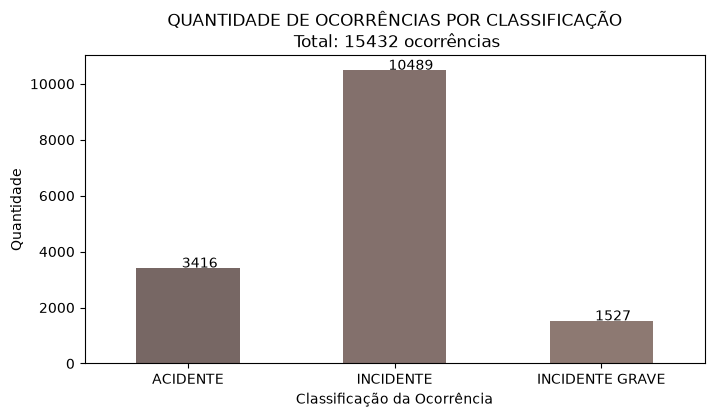

In [161]:
classe_ocorrencia = analise.groupby('Classificação')['Contagem'].sum().plot(kind='bar', figsize=(8,4), color=random.choice(colors), alpha=.7)

for p in classe_ocorrencia.patches:
    b=p.get_bbox()
    classe_ocorrencia.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.03, b.y1 + 15))

plt.xticks(rotation=0)
plt.xlabel('Classificação da Ocorrência')
plt.ylabel('Quantidade')
plt.title('QUANTIDADE DE OCORRÊNCIAS POR CLASSIFICAÇÃO\n Total: '+str(analise['Contagem'].sum())+' ocorrências')
plt.show()

Gráfico acima evidência que as ocorrências são dividas três classificações: Acidente, Incidente e Incidente Grave. Observe que este arquivo trata ocorrências envolvendo aeronaves de Janeiro de 2007 a Abril de 2026, últimos 19 anos. Estas aconteceram por falha humana, de procedimentos e/ou falha técnica.

Após classificação das ocorrências, reponderei:

**Quais os tipos de ocorrências catalogadas e a sua frequência nestes últimos anos?**

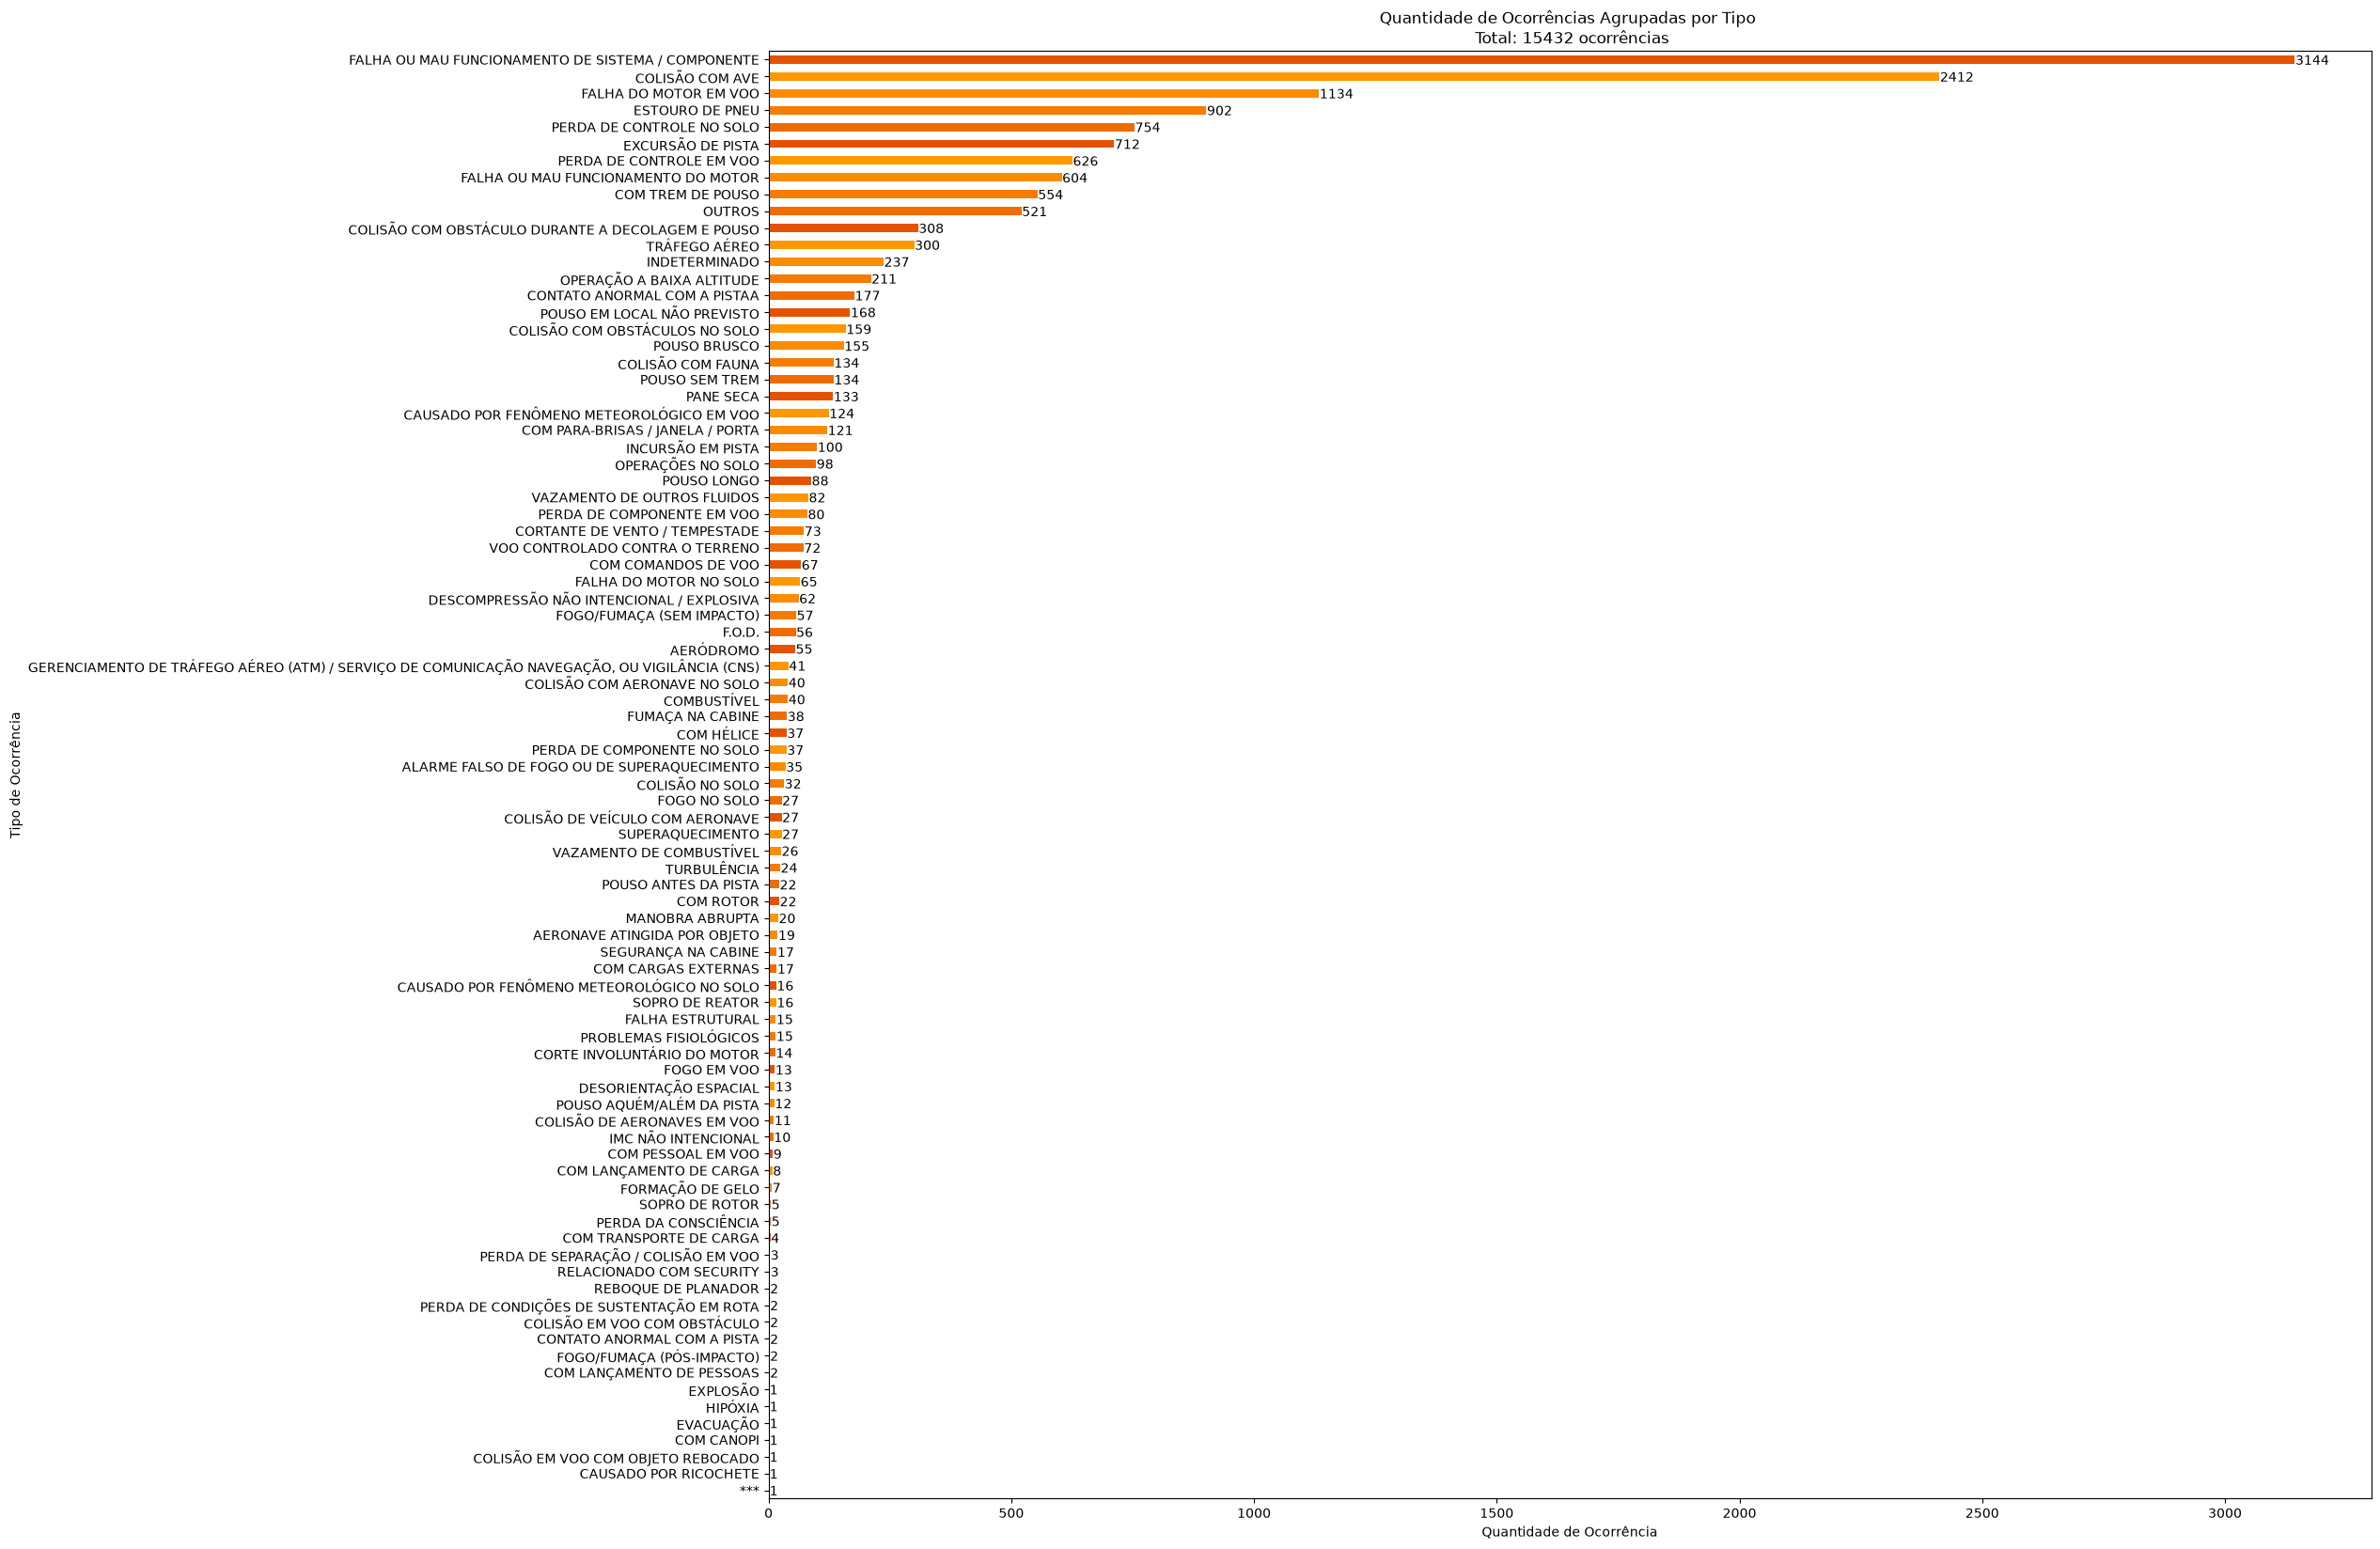

In [162]:
ax = analise.groupby('Tipo de Ocorrência')['Contagem'].sum().sort_values().plot(kind='barh', color=random.choice(colors), figsize=(22,20))

for p in ax.patches:
    b=p.get_bbox()
    ax.annotate("{:.0f}".format(b.x1 + b.x0), (p.get_x() + p.get_width() + 1, p.get_y() - 0.05))

plt.title('Quantidade de Ocorrências Agrupadas por Tipo \n Total: ' + str(analise['Contagem'].sum()) + ' ocorrências')
plt.ylabel('Tipo de Ocorrência')
plt.xlabel('Quantidade de Ocorrência')
plt.show()

As etapas para gerar o gráfico acima listando e quantificando quantidade de ocorrências por tipo, foi necessário agrupar dois dataframes, **ocorrencia** e **tipo_ocorrencia**, somando a quantidade de por cada tipo listado e relacionado de muitos para 1.
De acordo com a percepção do plot acima, as maiores causas de ocorrências são "falha ou mau funcionamento de sistema / componente" 3144 de 15432 ocorrências. Embora tais causas nos remetam a falha humana na operação, não podemos levar isto como uma regra. Uma perda de controle em vôo pode dever-se desde incompetência técnica até falha em dispositivos como o radar. Todavia, a escala destes três principais motivos é uma causa a se preocupar.

Vamos responder a próxima pergunta:

**Como tem sido a progressão desses últimos anos? Tiveram menos ocorrências ou mais?**

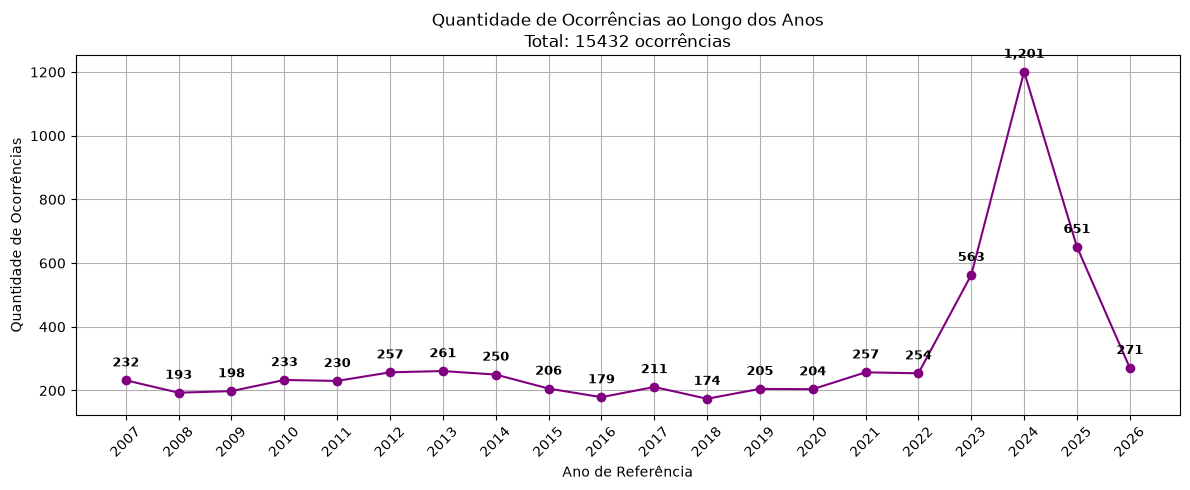

In [163]:
plotagem_data = analise.copy()

# Converter para datetime
plotagem_data['Dia da Ocorrência'] = pd.to_datetime(
    plotagem_data['Dia da Ocorrência'],
    errors='coerce'
)

# Extrair ano
plotagem_data['Ano'] = plotagem_data['Dia da Ocorrência'].dt.year

# Agrupar por ano
dados_ano = plotagem_data.groupby('Ano')['Contagem'].sum()

# Criar gráfico
fig, ax = plt.subplots(figsize=(12, 5))

dados_ano.plot(
    kind='line',
    marker='o',
    color='purple',
    grid=True,
    ax=ax
)

# Inserir quantidade de ocorrências em cada ponto
for x, y in zip(dados_ano.index, dados_ano.values):
    ax.annotate(
        f'{y:,.0f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

plt.title(
    'Quantidade de Ocorrências ao Longo dos Anos\n'
    + 'Total: '
    + str(analise['Contagem'].sum())
    + ' ocorrências'
)

plt.ylabel('Quantidade de Ocorrências')
plt.xlabel('Ano de Referência')
plt.xticks(dados_ano.index, rotation=45)

plt.tight_layout()
plt.show()

O período avaliado neste trabalho de análise de dados compreende 2007 - 2026, e neste tempo analisado, saimos de 205 ocorrências em 2019, onde se inicia um aumento leve para 257 ocorrências em 2021, mas entre 2024 a 2025 o número destes eventos foi isano, chegando em 2024 ao pico de 1201 ocorrências. A progressão de ocorrências aéres nos últimos anos tem crescido assustadoramente. Enquanto em 2008 tivemos menos que 198 ocorrências.

**E quanto aos estados? Quais foram os que mais registraram ocorrências?**

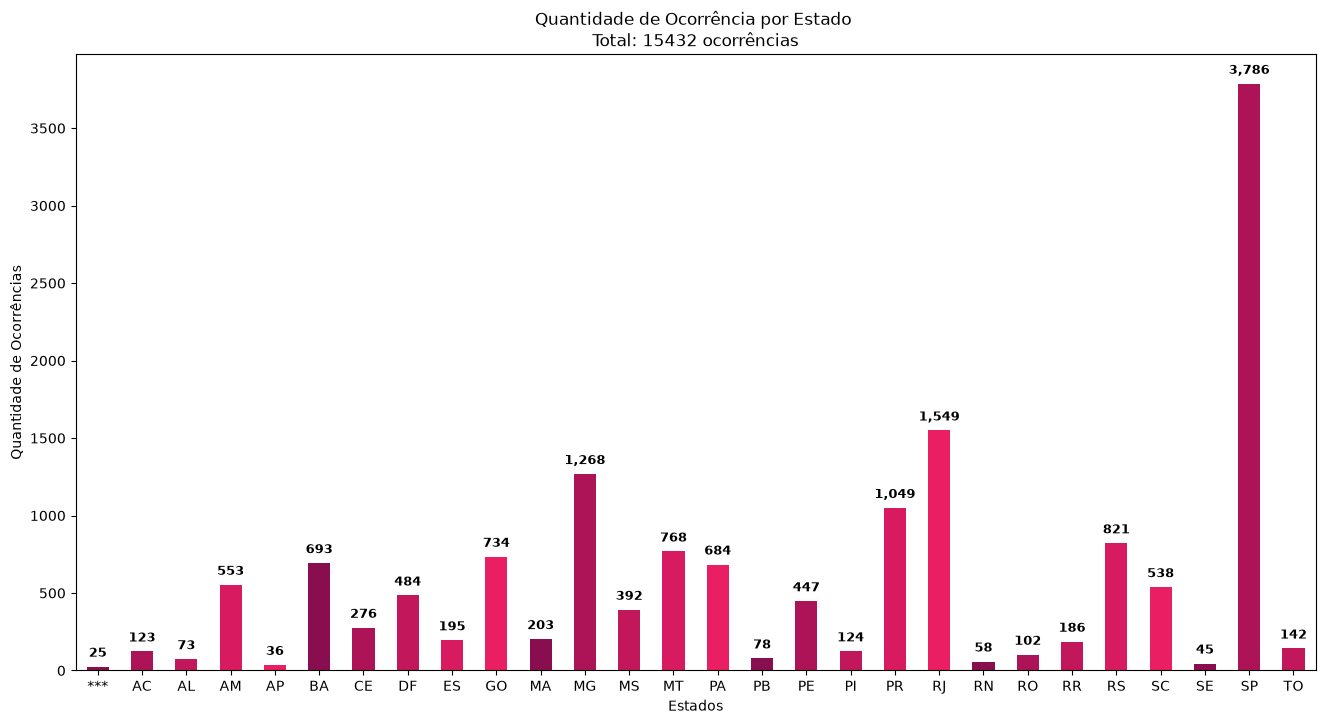

In [164]:
ax_estado = analise.groupby('UF')['Contagem'].sum().plot(kind='bar', color=random.choice(colors), figsize=(16,8))
# Adicionar valores no topo de cada barra
for barra in ax_estado.patches:
    valor = barra.get_height()

    ax_estado.annotate(
        f'{valor:,.0f}',
        (barra.get_x() + barra.get_width() / 2, valor),
        ha='center',
        va='bottom',
        xytext=(0, 5),
        textcoords='offset points',
        fontsize=9,
        fontweight='bold'
    )
plt.xlabel('Estados')
plt.ylabel('Quantidade de Ocorrências')
plt.title('Quantidade de Ocorrência por Estado \nTotal: ' + str(analise['Contagem'].sum()) + ' ocorrências')
plt.xticks(rotation=0)
plt.show()

Unidade Federativa de SP - São Paulo detém a maior incidência de ocorrências. Vale um questionamento sobre a modalidade de vôos no estado que gere essa quantidade de eventos, aviação executiva ou de carreira.


## **Analisando o dataset de aeronaves**

Agora iremos partir para o segundo conjunto de dados deste estudo: o dataset de aeronaves. Este arquivo possui informações acerca dos veículos que estavam envolvidos nas ocorrências registradas dos últimos anos. Primeiro, realizarei a fase de limpeza dos dados (semelhante ao feito anteriormente), depois, irei trazer alguns Insights a partir da visualização dos dados. Vamos começar?


## **Limpeza dos Dados (Data Cleaning**

O arquivo "aeronave.csv" possui 20 colunas com informações sobre os aviões. Muitos desses dados não são de grande valia para esse estudo, como matricula da aeronave, seu código, peso máximo na decolagem e categoria de registro. Inicialmente, irei removê-los do DataFrame para melhor visualização, depois, converterei colunas indevidas com seu respectivo tipo de arquivo, seguido por processos como renomeação de colunas e eliminação de dados nulos.

Abaixo, apresento as primeiras linhas do arquivo.

In [165]:
aeronave.head(5)

,codigo_ocorrencia2,aeronave_matricula,aeronave_tipo_equipamento,aeronave_fabricante,aeronave_modelo,aeronave_tipo_icao,aeronave_motor_tipo,anv_motor_qtd,anv_motor_descricao_qtd,aeronave_pmd,aeronave_assentos,aeronave_ano_fabricacao,aeronave_pais_fabricante,aeronave_pais_registro,aeronave_voo_origem,aeronave_voo_destino,aeronave_fase_operacao,aeronave_tipo_operacao,aeronave_nivel_dano,aeronave_fatalidades_total
0,88808,CCBGU,AVIÃO,BOEING COMPANY,B787-9,B789,JATO,2,BIMOTOR,253000.0,0.0,2018.0,CHILE,CHILE,GOVERNADOR ANDRÉ FRANCO MONTORO,JOHN F. KENNEDY INTERNATIONAL AIRPORT,SUBIDA,REGULAR,NENHUM,0.0
1,88804,CCBEN,AVIÃO,AIRBUS S.A.S.,A321-211,A321,JATO,2,BIMOTOR,89000.0,0.0,0.0,CHILE,CHILE,AEROPORTO INTERNACIONAL DE SANTIAGO,GOVERNADOR ANDRÉ FRANCO MONTORO,ESTACIONAMENTO,REGULAR,LEVE,0.0
2,88794,N412MC,AVIÃO,BOEING COMPANY,747-400 SERIES,B744,JATO,2,BIMOTOR,397000.0,0.0,0.0,ESTADOS UNIDOS,ESTADOS UNIDOS,ANTONIO CARLOS JOBIM / GALEÃO,VIRACOPOS,TÁXI,REGULAR,NENHUM,0.0
3,88783,CCBAC,AVIÃO,AIRBUS S.A.S,A320-233,A323,JATO,2,BIMOTOR,242000.0,0.0,0.0,CHILE,CHILE,AEROPORTO INTERNACIONAL JORGE CHÁVEZ,ANTONIO CARLOS JOBIM / GALEÃO,POUSO,REGULAR,LEVE,0.0
4,88769,PSGFC,AVIÃO,BOEING COMPANY,737-8EH,B738,JATO,2,BIMOTOR,75214.0,8.0,2007.0,BRASIL,BRASIL,GOVERNADOR ANDRÉ FRANCO MONTORO,DEPUTADO LUÍS EDUARDO MAGALHÃES,POUSO,REGULAR,NENHUM,0.0
